# 01 — Exploratory Data Analysis & Tracking Quality Audit

This notebook generates the deterministic 14-day synthetic checkout redesign dataset, audits injected tracking anomalies via strict Pydantic v2 validation, and checks covariate randomization balance, daily traffic stability, funnel progression, and revenue distributions.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

%matplotlib inline
plt.rcParams['figure.dpi'] = 120


## 1. Data Generation & Quality Audit

In [2]:
from src.data_pipeline import clean_and_validate_data, generate_synthetic_ab_data
from src.schemas import ExperimentConfig

config = ExperimentConfig(seed=42, n_users=40000)
raw_df = generate_synthetic_ab_data(config)
clean_df, quality = clean_and_validate_data(raw_df)

quality_df = pd.DataFrame([quality.model_dump()]).T.rename(columns={0: 'value'})
display(quality_df)

,value
raw_rows,40600.000000
clean_rows,39880.000000
duplicates_removed,239.000000
mixed_group_users_removed,241.000000
invalid_revenue_removed,120.000000
invalid_funnel_removed,120.000000
retained_rate,0.982266


## 2. Randomization Balance Across Device & Channel

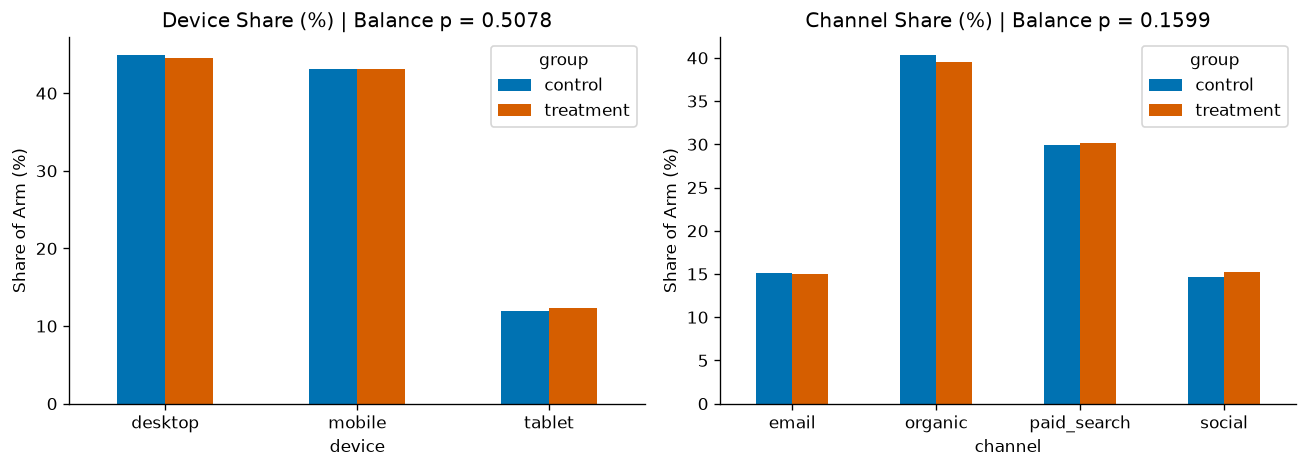

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, dim in zip(axes, ['device', 'channel']):
    ct = pd.crosstab(clean_df[dim], clean_df['group'])
    chi2, p_val, _, _ = stats.chi2_contingency(ct)
    shares = ct.div(ct.sum(axis=0), axis=1) * 100.0
    shares.plot(kind='bar', ax=ax, color=['#0072B2', '#D55E00'])
    ax.set_title(f'{dim.title()} Share (%) | Balance p = {p_val:.4f}')
    ax.set_ylabel('Share of Arm (%)')
    ax.tick_params(axis='x', rotation=0)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

## 3. Daily Traffic Stability (14-Day Window)

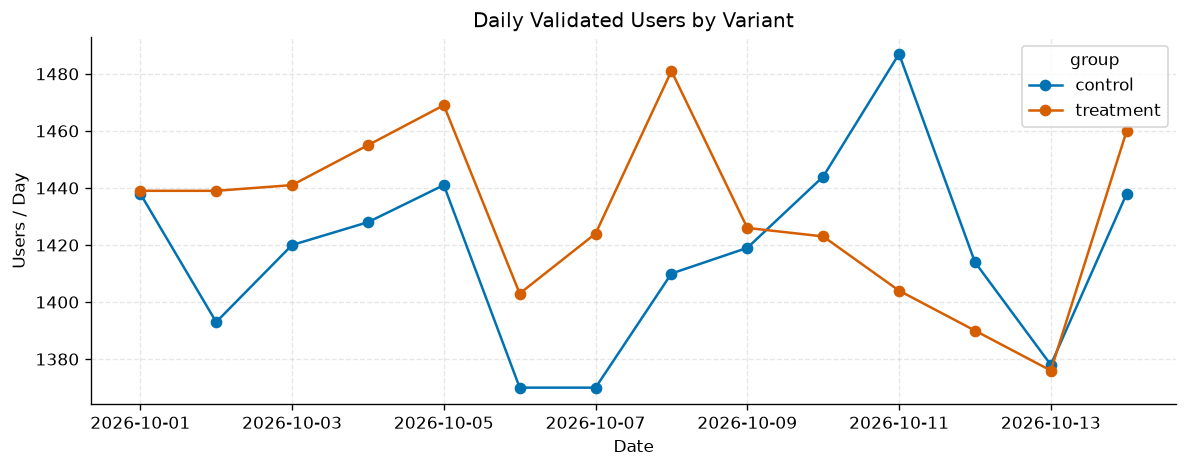

group,control,treatment
count,14.0,14.0
mean,1417.9,1430.7
std,32.6,30.3
min,1370.0,1376.0
25%,1397.2,1408.8
50%,1419.5,1432.5
75%,1438.0,1451.5
max,1487.0,1481.0


In [4]:
clean_df['date'] = pd.to_datetime(clean_df['timestamp']).dt.date
daily_counts = clean_df.groupby(['date', 'group']).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(10, 4))
daily_counts.plot(ax=ax, marker='o', color=['#0072B2', '#D55E00'])
ax.set_title('Daily Validated Users by Variant')
ax.set_ylabel('Users / Day')
ax.set_xlabel('Date')
ax.grid(alpha=0.3, linestyle='--')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()
display(daily_counts.describe().round(1))

## 4. Funnel Drop-off Overview

In [5]:
stages = ['viewed_landing', 'clicked_cta', 'started_checkout', 'converted']
funnel_summary = clean_df.groupby('group')[stages].mean().T * 100.0
funnel_summary['abs_diff_pp'] = funnel_summary['treatment'] - funnel_summary['control']
funnel_summary['rel_lift_pct'] = (
    funnel_summary['abs_diff_pp'] / funnel_summary['control']
) * 100.0
display(funnel_summary.round(2))

group,control,treatment,abs_diff_pp,rel_lift_pct
viewed_landing,94.71,95.13,0.43,0.45
clicked_cta,45.06,47.09,2.03,4.51
started_checkout,22.52,24.01,1.49,6.59
converted,9.69,11.54,1.84,19.03


## 5. Revenue per User (RPU) & Average Order Value (AOV)

Revenue per User (All Users):


,count,mean,std,median
group,,,,
control,19850,5.99,21.02,0.0
treatment,20030,7.21,22.85,0.0


Average Order Value (Converters Only):


,count,mean,std,median,p95
group,,,,,
control,1924,61.78,33.35,53.90,124.37
treatment,2311,62.46,32.81,55.55,123.38


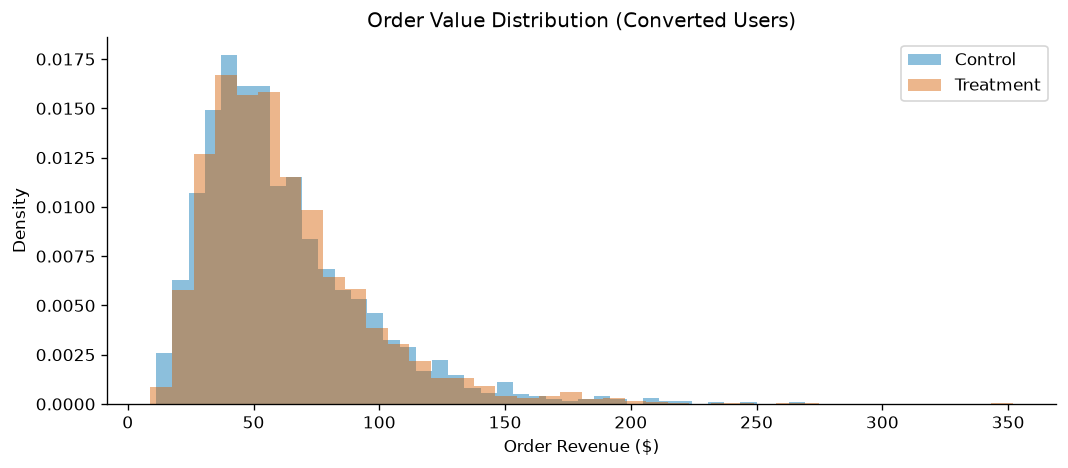

In [6]:
rpu_stats = clean_df.groupby('group')['revenue'].agg(['count', 'mean', 'std', 'median'])
aov_stats = (
    clean_df.loc[clean_df['converted']]
    .groupby('group')['revenue']
    .agg(['count', 'mean', 'std', 'median', lambda s: np.percentile(s, 95)])
    .rename(columns={'<lambda_0>': 'p95'})
)
print('Revenue per User (All Users):')
display(rpu_stats.round(2))
print('Average Order Value (Converters Only):')
display(aov_stats.round(2))

fig, ax = plt.subplots(figsize=(9, 4))
for grp, col in [('control', '#0072B2'), ('treatment', '#D55E00')]:
    vals = clean_df.loc[(clean_df['group'] == grp) & clean_df['converted'], 'revenue']
    ax.hist(vals, bins=40, alpha=0.45, density=True, label=grp.title(), color=col)
ax.set_title('Order Value Distribution (Converted Users)')
ax.set_xlabel('Order Revenue ($)')
ax.set_ylabel('Density')
ax.legend()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()